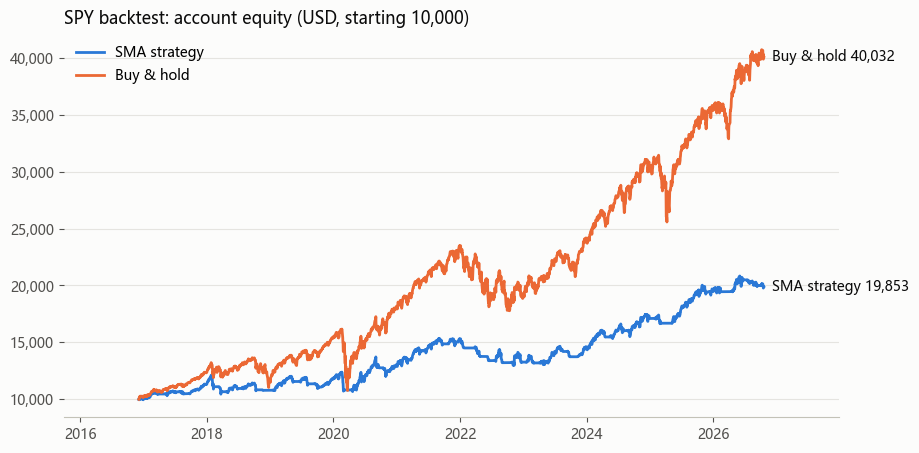

In [5]:
# 策略：10 日 / 30 日均线逐步加减仓（参数见 config.toml [strategy]）
#       每天收盘后算信号，第二天开盘成交：
#         10 日均线 > 30 日均线 → 加仓 10%（占满仓的比例），直到满仓；
#         10 日均线 ≤ 30 日均线 → 卖出当前持仓的 50%。
#       手续费按盈透固定费率（每股 0.005 USD，单笔最低 1 USD）。
#       对比基准“一直持有”：第一天全部资金买入后不再交易。
# 买入：SPY（SPDR 标普 500 ETF，跟踪美国标普 500 指数），只交易这一个标的；
#       价格用复权日线（分红已计入），最近 10 年，初始资金 10,000 USD。
#
# 图：两种做法的账户总资产随时间变化。数据来自 backtest.py 生成的 results/backtest_SPY.csv，
#     重新回测后再运行本单元格即可更新。
import pandas as pd
import matplotlib.pyplot as plt

symbol = "SPY"
df = pd.read_csv(f"../results/backtest_{symbol}.csv", parse_dates=["date"])

lines = [("equity", "SMA strategy", "#2a78d6"), ("buy_hold_equity", "Buy & hold", "#eb6834")]
fig, ax = plt.subplots(figsize=(10, 5), facecolor="#fcfcfb")
ax.set_facecolor("#fcfcfb")
for col, name, color in lines:
    ax.plot(df["date"], df[col], color=color, linewidth=2, label=name)
    # 在线的末端直接标出名字和最终资产
    ax.annotate(f"{name} {df[col].iloc[-1]:,.0f}", (df["date"].iloc[-1], df[col].iloc[-1]),
                xytext=(6, 0), textcoords="offset points", va="center", color="#0b0b0b", fontsize=10)

ax.set_title(f"{symbol} backtest: account equity (USD, starting {df['equity'].iloc[0]:,.0f})", loc="left", color="#0b0b0b")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")
ax.grid(axis="y", color="#e5e4e0", linewidth=0.8)
ax.tick_params(colors="#52514e")
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color("#c3c2b7")
ax.legend(loc="upper left", frameon=False)
ax.margins(x=0.12)  # 右侧留白放标签
plt.show()


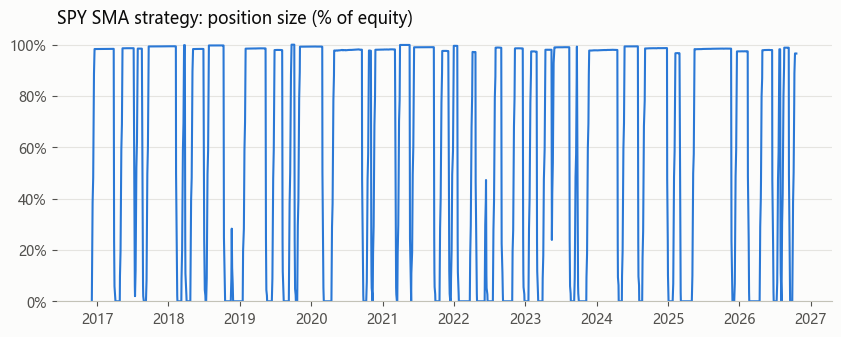

In [6]:
# 策略：10 日 / 30 日均线逐步加减仓（参数见 config.toml [strategy]）
#       每天收盘后算信号，第二天开盘成交：
#         10 日均线 > 30 日均线 → 加仓 10%（占满仓的比例），直到满仓；
#         10 日均线 ≤ 30 日均线 → 卖出当前持仓的 50%。
#       手续费按盈透固定费率（每股 0.005 USD，单笔最低 1 USD）。
#       对比基准“一直持有”：第一天全部资金买入后不再交易。
# 买入：SPY（SPDR 标普 500 ETF，跟踪美国标普 500 指数），只交易这一个标的；
#       价格用复权日线（分红已计入），最近 10 年，初始资金 10,000 USD。
#
# 图：策略每天收盘时的实际仓位（持股市值 / 总资产）。0% = 全部现金，100% = 满仓。
#     数据同样来自 results/backtest_SPY.csv，需要先运行上一个单元格。
position = df["shares"] * df["close"] / df["equity"] * 100

fig, ax = plt.subplots(figsize=(10, 3.5), facecolor="#fcfcfb")
ax.set_facecolor("#fcfcfb")
ax.plot(df["date"], position, color="#2a78d6", linewidth=1.5)

ax.set_title(f"{symbol} SMA strategy: position size (% of equity)", loc="left", color="#0b0b0b")
ax.set_ylim(0, 105)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
ax.grid(axis="y", color="#e5e4e0", linewidth=0.8)
ax.tick_params(colors="#52514e")
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color("#c3c2b7")
plt.show()
